In [3]:
import pandas as pd 
import numpy as np

In [4]:
#Importing the dataset
reg_path= "../../data/Regression_datasets/bfsi.csv"
bfsi_reg_data= pd.read_csv(reg_path)
print(bfsi_reg_data.head())

         income  credit_limit  txn_frequency         spend
0  29250.810247  17543.120644             24  46792.808965
1  49760.206810  18498.590717             29  44807.380291
2  56881.250972  23963.608190             15  61290.095565
3  50860.687702  16304.715063             18  39222.867023
4  43891.640345  14582.996443             17  39005.804117


In [5]:
def data_exploration(data):
    print("Data Exploration:")
    print("Shape of the dataset:", data.shape)
    print("\nColumns in the dataset:", data.columns)
    print("\nData types of each column:\n", data.dtypes)
    print("\nMissing values in each column:\n", data.isnull().sum())
    print("\nStatistical summary of the dataset:\n", data.describe())

def get_correlation_matrix(data):
    correlation_matrix = data.corr()
    return correlation_matrix

def plot_correlation_matrix(correlation_matrix):
    import matplotlib.pyplot as plt
    import seaborn as sns

    plt.figure(figsize=(6, 4))
    sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
    plt.title("Correlation Matrix")
    plt.show()

def feature_selection(data, target_variable):
    from sklearn.feature_selection import SelectKBest, f_regression

    X = data.drop(columns=[target_variable])
    y = data[target_variable]

    # Select the top 5 features based on univariate linear regression tests
    selector = SelectKBest(score_func=f_regression, k=5)
    selector.fit(X, y)

    selected_features = X.columns[selector.get_support()]
    return selected_features

def normalize_data(data):
    from sklearn.preprocessing import MinMaxScaler

    scaler = MinMaxScaler()
    normalized_data = pd.DataFrame(scaler.fit_transform(data), columns=data.columns)
    return normalized_data

def handle_missing_values(data):
    # Fill missing values with the mean of the column
    data_filled = data.fillna(data.mean())
    return data_filled

def linear_regression_model(X, y):
    from sklearn.model_selection import train_test_split
    from sklearn.linear_model import LinearRegression
    from sklearn.metrics import mean_squared_error, r2_score

    # Split the dataset into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Create a linear regression model
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Make predictions on the test set
    y_pred = model.predict(X_test)

    # Evaluate the model
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print("Mean Squared Error:", mse)
    print("R-squared:", r2)

    return model

def cross_validation(model, X, y, cv=5):
    from sklearn.model_selection import cross_val_score

    scores = cross_val_score(model, X, y, cv=cv)
    print("Cross-validation scores:", scores)
    print("Average CV score:", scores.mean())

In [6]:
#data exploration
data_exploration(bfsi_reg_data)

Data Exploration:
Shape of the dataset: (10000, 4)

Columns in the dataset: Index(['income', 'credit_limit', 'txn_frequency', 'spend'], dtype='object')

Data types of each column:
 income           float64
credit_limit     float64
txn_frequency      int64
spend            float64
dtype: object

Missing values in each column:
 income           0
credit_limit     0
txn_frequency    0
spend            0
dtype: int64

Statistical summary of the dataset:
               income  credit_limit  txn_frequency         spend
count   10000.000000  10000.000000   10000.000000  10000.000000
mean    50053.335170  19928.205083      20.006100  48967.353082
std     14874.482526   5013.287222       4.486544  10139.308299
min     -5119.095095   1962.142592       5.000000  11775.932609
25%     40019.367387  16601.688213      17.000000  42115.858147
50%     50125.008858  19942.054393      20.000000  48942.596072
75%     60130.632514  23233.431971      23.000000  55741.759445
max    103199.650524  38403.91086

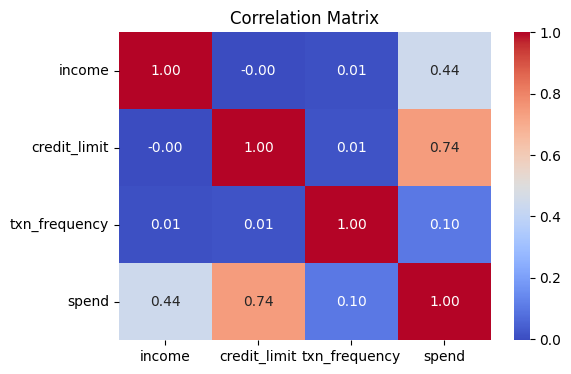

In [7]:
bfsi_correlation_matrix = get_correlation_matrix(bfsi_reg_data)
plot_correlation_matrix(bfsi_correlation_matrix)

In [8]:
import data_utils as du
du.data_exploration(bfsi_reg_data)

DATA EXPLORATION
Shape of dataset: 10000 rows, 4 columns

Columns: ['income', 'credit_limit', 'txn_frequency', 'spend']

Data Types:
 income           float64
credit_limit     float64
txn_frequency      int64
spend            float64
dtype: object

Missing Values:
 income           0
credit_limit     0
txn_frequency    0
spend            0
dtype: int64

Statistical Summary:
               income  credit_limit  txn_frequency         spend
count   10000.000000  10000.000000   10000.000000  10000.000000
mean    50053.335170  19928.205083      20.006100  48967.353082
std     14874.482526   5013.287222       4.486544  10139.308299
min     -5119.095095   1962.142592       5.000000  11775.932609
25%     40019.367387  16601.688213      17.000000  42115.858147
50%     50125.008858  19942.054393      20.000000  48942.596072
75%     60130.632514  23233.431971      23.000000  55741.759445
max    103199.650524  38403.910866      40.000000  87473.978198


In [9]:
X = bfsi_reg_data.drop(columns=['spend'],axis=1)  #
y = bfsi_reg_data['spend']  

In [10]:
model, mse, r2, y_test, y_pred = du.linear_regression_model(X, y)


Mean Squared Error: 24597423.0625
R-squared: 0.7562


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [11]:
du.cross_validation(model, X, y, cv=5)

5-Fold Cross-Validation (r2): [0.7632673  0.76858292 0.7488672  0.75760757 0.75129224]
Average CV score: 0.7579 (± 0.0073)


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: i

array([0.7632673 , 0.76858292, 0.7488672 , 0.75760757, 0.75129224])

Over all prediction around 75% percent around getting aroung cross validation 


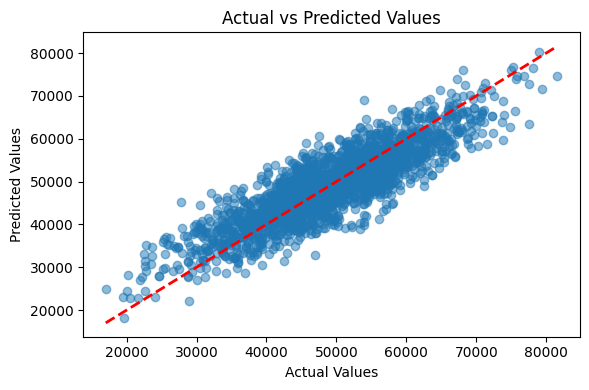

In [12]:

du.plot_actual_vs_predicted(y_test, y_pred)

In [14]:
len(y_pred)

2000